# Exploração dos dados: Breast Cancer Wisconsin

Este notebook explora a base usada para testar o Map-Optimize-Learn (MOL). O objetivo é conhecer os dados
e levantar o que importa para o método: as escalas das features, o quanto cada uma separa as classes e
como elas se correlacionam.

A base tem 569 pacientes. Cada linha traz 30 medidas do núcleo das células, obtidas de uma imagem de
punção da mama, e o diagnóstico (benigno ou maligno).

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from mol.data import CSV_PADRAO

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
CORES = {"Benigno": "#4C9BE8", "Maligno": "#F2994A"}

## 1. Carregando os dados

In [2]:
df = pd.read_csv(CSV_PADRAO)
print(f"{df.shape[0]} linhas e {df.shape[1]} colunas")
df.head()

569 linhas e 32 colunas


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [3]:
print("Valores faltantes:", int(df.isna().sum().sum()))
print("Linhas duplicadas:", int(df.duplicated().sum()))
print("Tipos das colunas:", df.dtypes.value_counts().to_dict())

Valores faltantes: 0
Linhas duplicadas: 0
Tipos das colunas: {dtype('float64'): 30, dtype('int64'): 1, dtype('O'): 1}


Não há valores faltantes nem linhas duplicadas. A coluna `id` só identifica o paciente e não entra na
análise. O diagnóstico vem como `M` (maligno) ou `B` (benigno).

In [4]:
df = df.drop(columns=["id"])
df["diagnostico"] = df.pop("diagnosis").map({"B": "Benigno", "M": "Maligno"})
features = [c for c in df.columns if c != "diagnostico"]
len(features)

30

## 2. O alvo

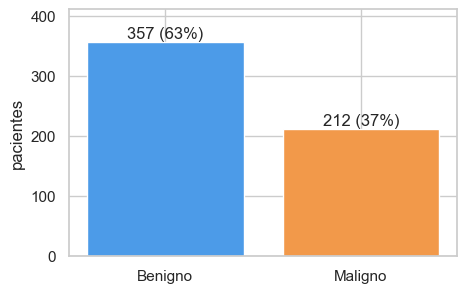

In [5]:
contagem = df["diagnostico"].value_counts()
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.bar(contagem.index, contagem.values, color=[CORES[c] for c in contagem.index])
for i, v in enumerate(contagem.values):
    ax.text(i, v + 5, f"{v} ({v / len(df):.0%})", ha="center")
ax.set_ylabel("pacientes")
ax.set_ylim(0, contagem.max() * 1.15)
plt.show()

As classes são desbalanceadas: 37% dos pacientes são malignos. Por isso a avaliação dos modelos usa
divisão estratificada e acurácia balanceada, que não se deixa enganar pela classe majoritária.

## 3. Como as features são organizadas

São 10 medidas do núcleo celular, cada uma em três versões: a média (`_mean`), o erro padrão (`_se`) e o
pior valor (`_worst`, a média dos três maiores).

In [6]:
medidas = sorted({c.rsplit("_", 1)[0] for c in features})
pd.DataFrame({"medida": medidas,
              "versões": [", ".join(c.rsplit("_", 1)[1] for c in features if c.rsplit("_", 1)[0] == m)
                          for m in medidas]})

,medida,versões
0,area,"mean, se, worst"
1,compactness,"mean, se, worst"
2,concave points,"mean, se, worst"
3,concavity,"mean, se, worst"
4,fractal_dimension,"mean, se, worst"
5,perimeter,"mean, se, worst"
6,radius,"mean, se, worst"
7,smoothness,"mean, se, worst"
8,symmetry,"mean, se, worst"
9,texture,"mean, se, worst"


In [7]:
df[features].describe().T[["mean", "std", "min", "50%", "max"]].round(4)

,mean,std,min,50%,max
radius_mean,14.1273,3.5240,6.9810,13.3700,28.1100
texture_mean,19.2896,4.3010,9.7100,18.8400,39.2800
perimeter_mean,91.9690,24.2990,43.7900,86.2400,188.5000
area_mean,654.8891,351.9141,143.5000,551.1000,2501.0000
smoothness_mean,0.0964,0.0141,0.0526,0.0959,0.1634
compactness_mean,0.1043,0.0528,0.0194,0.0926,0.3454
concavity_mean,0.0888,0.0797,0.0000,0.0615,0.4268
concave points_mean,0.0489,0.0388,0.0000,0.0335,0.2012
symmetry_mean,0.1812,0.0274,0.1060,0.1792,0.3040
fractal_dimension_mean,0.0628,0.0071,0.0500,0.0615,0.0974


### As escalas são muito diferentes

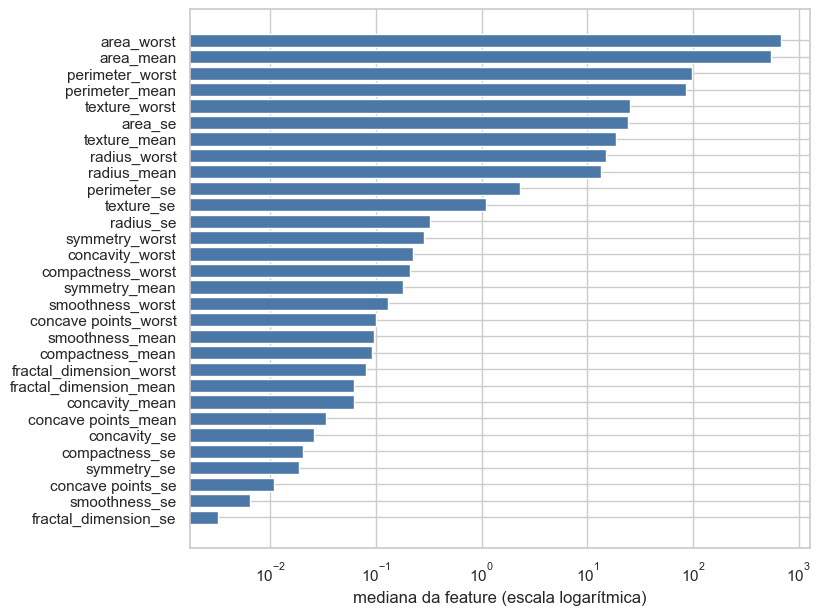

Maior mediana: area_worst = 686.5
Menor mediana: fractal_dimension_se = 0.0032


In [8]:
mediana = df[features].median().sort_values()
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(mediana.index, mediana.values, color="#4C78A8")
ax.set_xscale("log")
ax.set_xlabel("mediana da feature (escala logarítmica)")
plt.show()
print(f"Maior mediana: {mediana.index[-1]} = {mediana.iloc[-1]:.1f}")
print(f"Menor mediana: {mediana.index[0]} = {mediana.iloc[0]:.4f}")

As medianas vão de milésimos a centenas. Sem padronização, as features de área dominariam qualquer conta
que some ou compare colunas, como as do MOL. Por isso o primeiro passo do método é o z-score.

## 4. Separando treino e teste

Daqui em diante a exploração usa só o treino, com a mesma divisão dos experimentos (80/20, estratificada,
semente 42). O teste fica reservado para a avaliação final.

In [9]:
treino, teste = train_test_split(df, test_size=0.2, random_state=42, stratify=df["diagnostico"])
pd.DataFrame({"treino": treino["diagnostico"].value_counts(normalize=True).round(3),
              "teste": teste["diagnostico"].value_counts(normalize=True).round(3)})

,treino,teste
diagnostico,,
Benigno,0.626,0.632
Maligno,0.374,0.368


## 5. Distribuição das features por diagnóstico

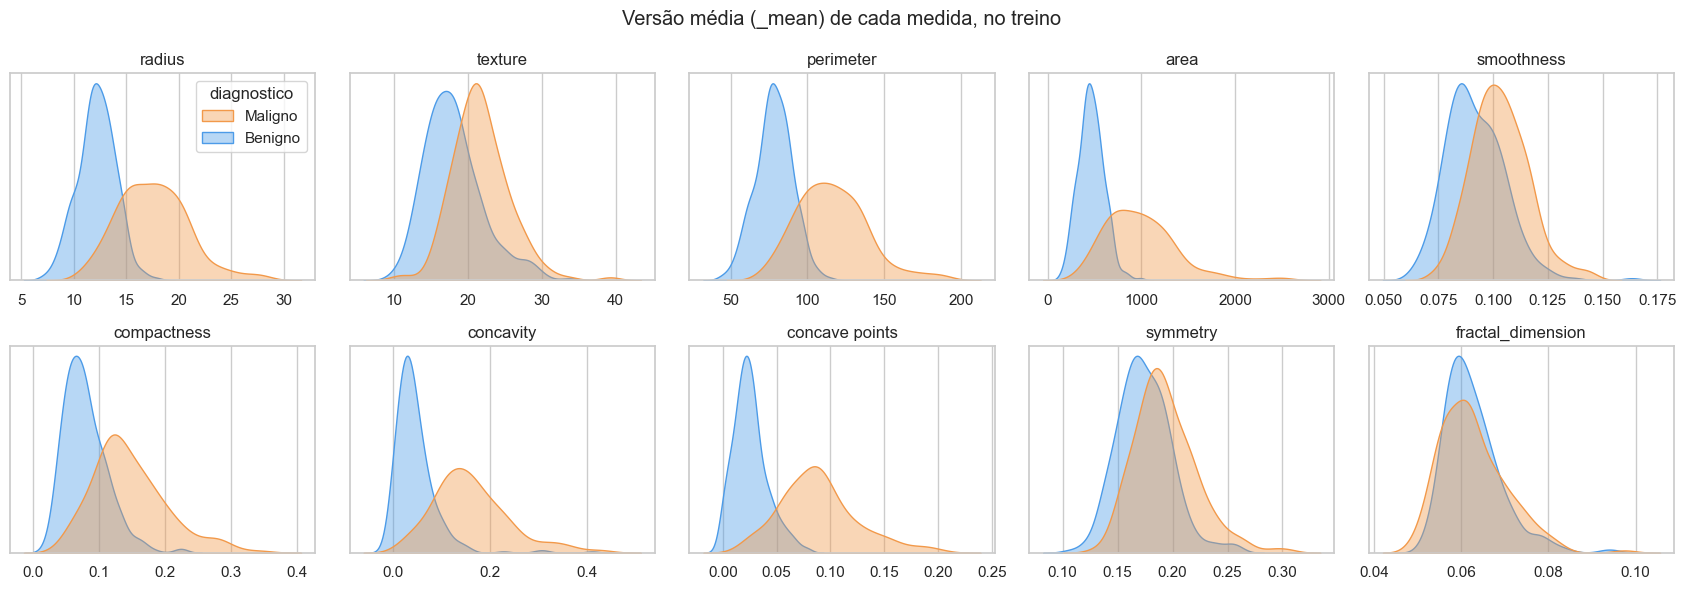

In [10]:
medias = [c for c in features if c.endswith("_mean")]
fig, eixos = plt.subplots(2, 5, figsize=(17, 6))
for ax, col in zip(eixos.ravel(), medias):
    sns.kdeplot(data=treino, x=col, hue="diagnostico", palette=CORES, fill=True, common_norm=False,
                alpha=0.4, ax=ax, legend=(col == medias[0]))
    ax.set_title(col.replace("_mean", ""))
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_yticks([])
fig.suptitle("Versão média (_mean) de cada medida, no treino")
fig.tight_layout()
plt.show()

As medidas de tamanho (raio, perímetro, área) e de forma (concavidade, pontos côncavos) separam bem as
duas classes. Textura e suavidade separam pouco, e simetria e dimensão fractal quase nada.

### Quanto cada feature separa as classes

Uma forma simples de medir isso é padronizar a feature e calcular a distância entre a média dos malignos e
a média dos benignos. É o critério de "distância euclidiana" usado na etapa Map do MOL.

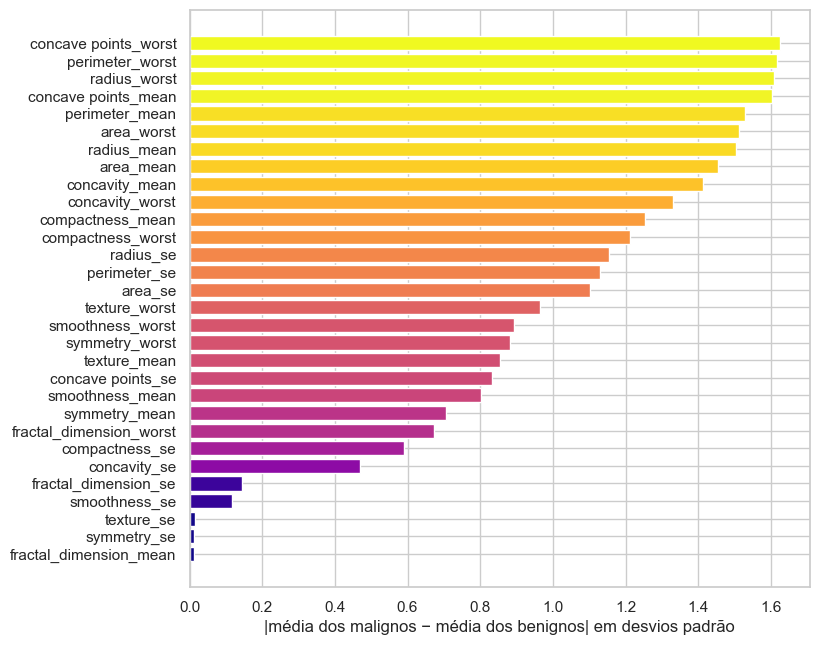

concave points_worst    1.625
perimeter_worst         1.618
radius_worst            1.607
concave points_mean     1.604
perimeter_mean          1.530
dtype: float64

In [11]:
z = (treino[features] - treino[features].mean()) / treino[features].std(ddof=0)
maligno = (treino["diagnostico"] == "Maligno").values
separacao = (z[maligno].mean() - z[~maligno].mean()).abs().sort_values()

fig, ax = plt.subplots(figsize=(8, 7.5))
ax.barh(separacao.index, separacao.values, color=plt.cm.plasma(separacao.values / separacao.max()))
ax.set_xlabel("|média dos malignos − média dos benignos| em desvios padrão")
plt.show()
separacao.sort_values(ascending=False).head(5).round(3)

As cinco melhores são todas de tamanho ou de pontos côncavos, na versão `_worst` ou `_mean`. No outro
extremo, algumas features de erro padrão e a dimensão fractal média não separam as classes.

## 6. Correlação entre as features

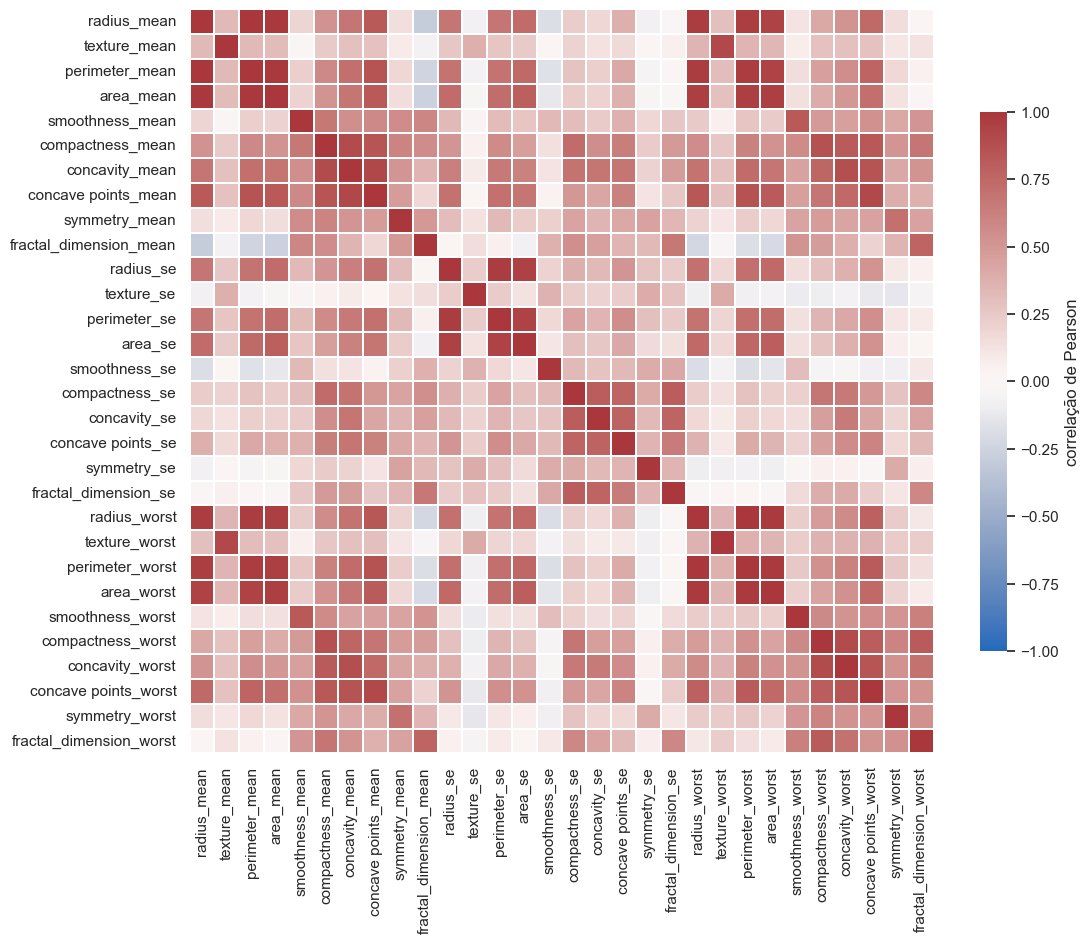

In [12]:
corr = treino[features].corr()
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, cmap="vlag", center=0, vmin=-1, vmax=1, square=True, linewidths=0.2,
            cbar_kws={"shrink": 0.7, "label": "correlação de Pearson"}, ax=ax)
plt.show()

In [13]:
pares = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename("correlação").sort_values(key=abs, ascending=False))
print(f"Pares com |correlação| acima de 0,9: {(pares.abs() > 0.9).sum()} de {len(pares)}")
pares.head(10).round(3).to_frame()

Pares com |correlação| acima de 0,9: 21 de 435


correlação
radius_mean     perimeter_mean        0.998
radius_worst    perimeter_worst       0.994
radius_mean     area_mean             0.987
perimeter_mean  area_mean             0.986
radius_worst    area_worst            0.983
perimeter_worst area_worst            0.977
radius_se       perimeter_se          0.975
perimeter_mean  perimeter_worst       0.970
                radius_worst          0.969
radius_mean     radius_worst          0.969

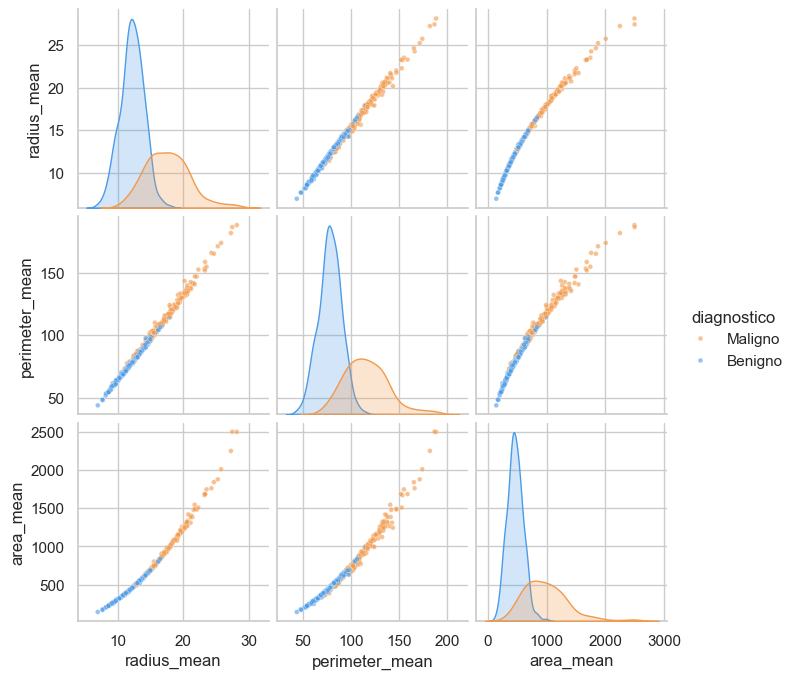

In [14]:
sns.pairplot(treino, vars=["radius_mean", "perimeter_mean", "area_mean"], hue="diagnostico",
             palette=CORES, plot_kws={"s": 12, "alpha": 0.6}, height=2.3)
plt.show()

Raio, perímetro e área medem quase a mesma coisa: um núcleo de raio grande tem perímetro e área grandes.
Isso tem duas consequências para o MOL:

- As features do topo do ranking são redundantes entre si. Pegar as primeiras do ranking repete informação.
- Existe estrutura de correlação para um arranjo espacial aproveitar. É a ideia do MOL v2: colocar features
  correlacionadas em pixels vizinhos.

## 7. Valores extremos

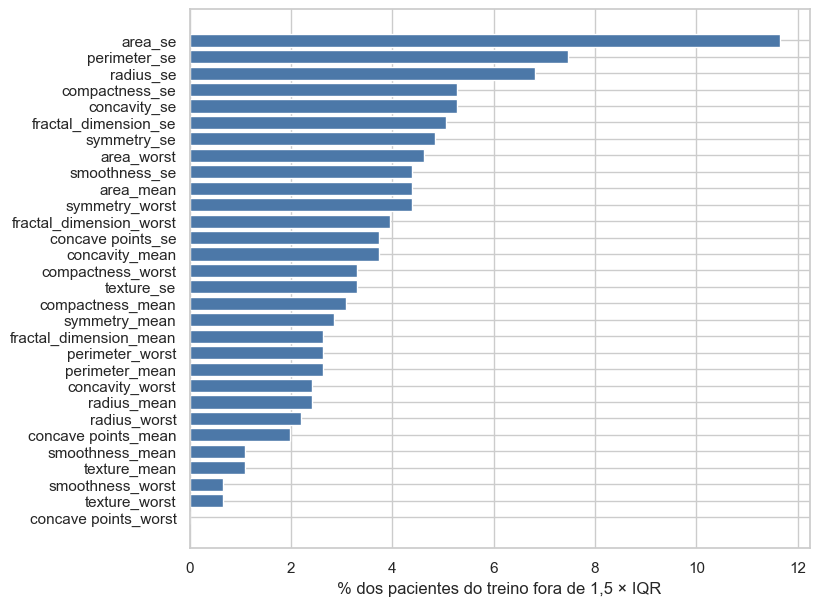

Features com algum valor extremo: 29 de 30
Valores extremos acima do limite superior: 100%
Valores extremos que são de pacientes malignos: 78%


In [15]:
q1, q3 = treino[features].quantile(0.25), treino[features].quantile(0.75)
iqr = q3 - q1
fora = ((treino[features] < q1 - 1.5 * iqr) | (treino[features] > q3 + 1.5 * iqr)).sum().sort_values()

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(fora.index, fora.values / len(treino) * 100, color="#4C78A8")
ax.set_xlabel("% dos pacientes do treino fora de 1,5 × IQR")
plt.show()

acima = treino[features] > q3 + 1.5 * iqr
abaixo = treino[features] < q1 - 1.5 * iqr
total = int(acima.values.sum() + abaixo.values.sum())
de_malignos = int((acima | abaixo)[treino["diagnostico"] == "Maligno"].values.sum())
print(f"Features com algum valor extremo: {int((fora > 0).sum())} de 30")
print(f"Valores extremos acima do limite superior: {acima.values.sum() / total:.0%}")
print(f"Valores extremos que são de pacientes malignos: {de_malignos / total:.0%}")

Quase todas as features têm valores extremos, concentrados nas de erro padrão e de área. Eles ficam na
cauda superior de distribuições assimétricas, e a maior parte pertence a tumores malignos, então carregam
informação. Não foram removidos. Na hora de desenhar as imagens do MOL, a escala de cinza é recortada para
que esses valores não escureçam o resto.

## 8. Visão em duas dimensões (PCA)

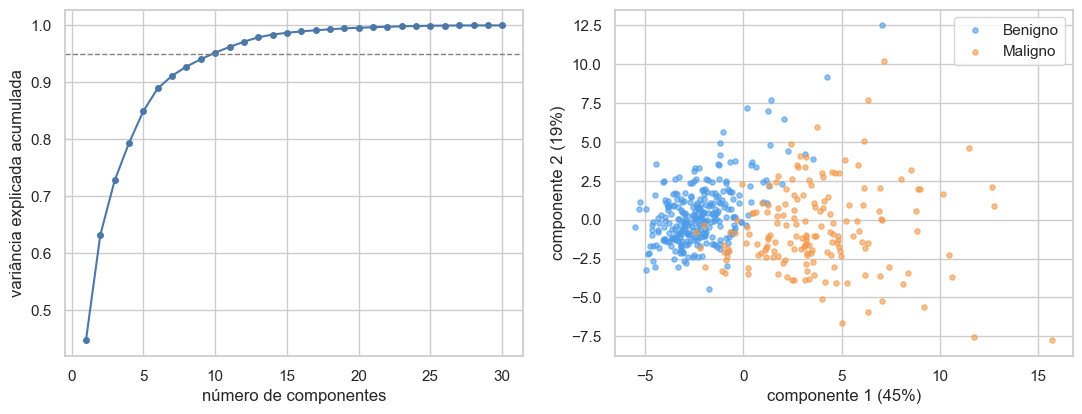

Componentes para explicar 95% da variância: 10 de 30


In [16]:
escala = StandardScaler().fit(treino[features])
pca = PCA().fit(escala.transform(treino[features]))
comp = pca.transform(escala.transform(treino[features]))[:, :2]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
acumulada = np.cumsum(pca.explained_variance_ratio_)
ax1.plot(range(1, 31), acumulada, marker="o", ms=4, color="#4C78A8")
ax1.axhline(0.95, color="gray", ls="--", lw=1)
ax1.set_xlabel("número de componentes")
ax1.set_ylabel("variância explicada acumulada")
for nome, cor in CORES.items():
    m = (treino["diagnostico"] == nome).values
    ax2.scatter(comp[m, 0], comp[m, 1], s=14, alpha=0.6, color=cor, label=nome)
ax2.set_xlabel(f"componente 1 ({pca.explained_variance_ratio_[0]:.0%})")
ax2.set_ylabel(f"componente 2 ({pca.explained_variance_ratio_[1]:.0%})")
ax2.legend()
plt.show()
print(f"Componentes para explicar 95% da variância: {int(np.argmax(acumulada >= 0.95)) + 1} de 30")

Dez componentes explicam 95% da variância das 30 features, o que confirma a redundância. No plano dos dois
primeiros componentes, as classes já aparecem quase separadas por uma reta.

## 9. O quanto o problema é fácil

Uma regressão logística com as features padronizadas dá uma referência antes de qualquer método mais
elaborado.

In [17]:
X = treino[features].values
y = (treino["diagnostico"] == "Maligno").astype(int).values
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
notas = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)), X, y,
                        cv=cv, scoring="balanced_accuracy")
print(f"Acurácia balanceada em 10 folds: {notas.mean():.3f} ± {notas.std():.3f}")

Acurácia balanceada em 10 folds: 0.972 ± 0.026


## 10. O que levar para a modelagem

- **Escalas:** as features vão de milésimos a milhares. Padronizar é obrigatório, e a padronização tem de
  ser ajustada só com o treino de cada fold.
- **Desbalanceamento:** 37% de malignos. Usar divisão estratificada e acurácia balanceada.
- **Redundância:** 30 features, mas cerca de 10 dimensões efetivas. Tamanho e forma concentram a separação
  entre as classes e são muito correlacionadas entre si.
- **Dificuldade:** um modelo linear já chega perto de 0,97. Sobra pouca margem para um método mais complexo
  mostrar ganho, e diferenças de 1 ponto ficam dentro da variação entre folds.

O notebook `02_aplicacao_mol.ipynb` aplica o MOL a estes dados.